In [1]:
import sys
import json
from pathlib import Path

_root = next(p for p in Path.cwd().resolve().parents if (p / '.git').exists() or (p / 'setup.py').exists())
for _p in (str(_root), str(_root / 'src')):
    if _p not in sys.path:
        sys.path.insert(0, _p)

from metab_processing.LinearRegression import signature_helpers as sh, signature_batch as sb
from metab_processing.LinearRegression.signature_configs import CONFIGS

cfg = CONFIGS['cervical']

In [2]:
membership = json.load(open(Path(cfg.cache_dir) / '_membership.json'))
print(f'{cfg.name}: loaded membership for {len(membership)} gene set(s)')

cervical: loaded membership for 30 gene set(s)


## cervical: target signatures -- membership, missing, present, factor-removed, remaining

In [3]:
print(f'===== {cfg.name} target signatures: membership + factor-removal =====')
for name in list(cfg.target_signatures) + list(cfg.neg_controls):
    m = membership.get(name, {})
    print(f'\n{name}')
    print(f"  present ({len(m.get('present', []))}): {m.get('present', [])}")
    print(f"  missing ({len(m.get('missing', []))}): {m.get('missing', [])}")
    print(f"  total: {m.get('total', 0)}")
    print(f"  factor_removed ({len(m.get('factor_removed', []))}): {m.get('factor_removed', [])}")
    print(f"  remaining ({len(m.get('remaining', []))}): {m.get('remaining', [])}")

===== cervical target signatures: membership + factor-removal =====

HALLMARK_IL2_STAT5_SIGNALING
  present (199): ['ABCB1', 'ADAM19', 'AGER', 'AHCY', 'AHNAK', 'AHR', 'ALCAM', 'AMACR', 'ANXA4', 'APLP1', 'ARL4A', 'BATF', 'BATF3', 'BCL2', 'BCL2L1', 'BHLHE40', 'BMP2', 'BMPR2', 'CA2', 'CAPG', 'CAPN3', 'CASP3', 'CCND2', 'CCND3', 'CCNE1', 'CCR4', 'CD44', 'CD48', 'CD79B', 'CD81', 'CD83', 'CD86', 'CDC42SE2', 'CDC6', 'CDCP1', 'CDKN1C', 'CISH', 'CKAP4', 'COCH', 'COL6A1', 'CSF1', 'CSF2', 'CST7', 'CTLA4', 'CTSZ', 'CXCL10', 'CYFIP1', 'DCPS', 'DENND5A', 'DHRS3', 'DRC1', 'ECM1', 'EEF1AKMT1', 'EMP1', 'ENO3', 'ENPP1', 'EOMES', 'ETFBKMT', 'ETV4', 'F2RL2', 'FAH', 'FGL2', 'FLT3LG', 'FURIN', 'GABARAPL1', 'GADD45B', 'GALM', 'GATA1', 'GBP4', 'GLIPR2', 'GPR65', 'GPR83', 'GPX4', 'GSTO1', 'GUCY1B1', 'HIPK2', 'HK2', 'HOPX', 'HUWE1', 'HYCC2', 'ICOS', 'IFITM3', 'IFNGR1', 'IGF1R', 'IGF2R', 'IKZF2', 'IKZF4', 'IL10', 'IL10RA', 'IL13', 'IL18R1', 'IL1R2', 'IL1RL1', 'IL2RA', 'IL2RB', 'IL3RA', 'IL4R', 'IRF4', 'IRF6', 'IR

## View helper -- `view(sig)` renders every cached run-spec for one signature

In [4]:
TARGETS = ([cfg.single_gene] if cfg.kind == 'colon' else []) + list(cfg.target_signatures) + list(cfg.neg_controls)
specs = sb.runspecs(cfg)


def view(sig):
    for spec in specs:
        res = sb.load_res(cfg, sig, spec['label'])
        if res is None:
            print('not yet computed:', sig, spec['label'])
            continue
        sh.plot_res(res, highlight_genes=membership.get(sig, {}).get('present', []),
                    title=f"{sig} | {spec['label']}")

## T-cell TARGET signatures

### HALLMARK_IL2_STAT5_SIGNALING

Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.


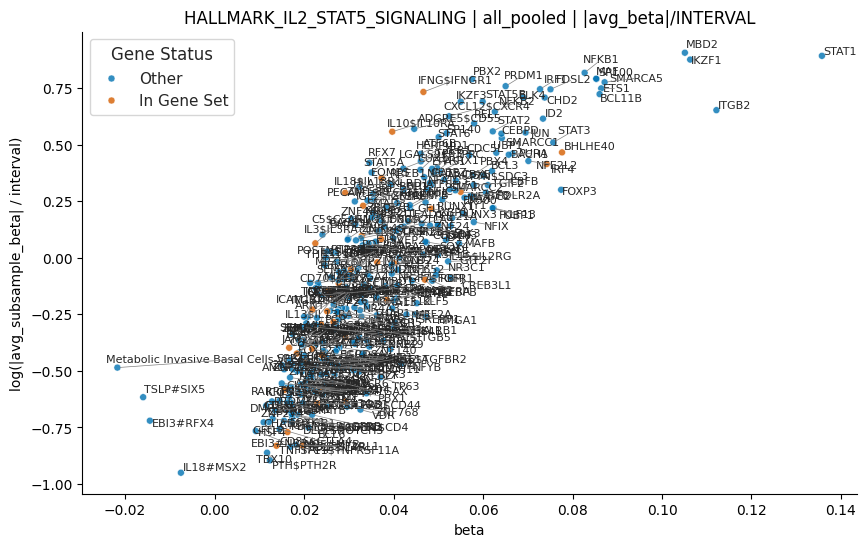

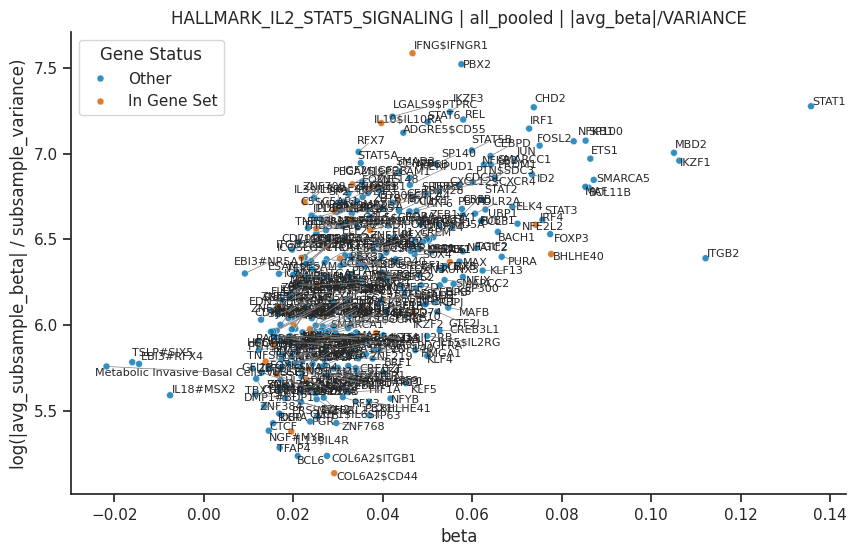

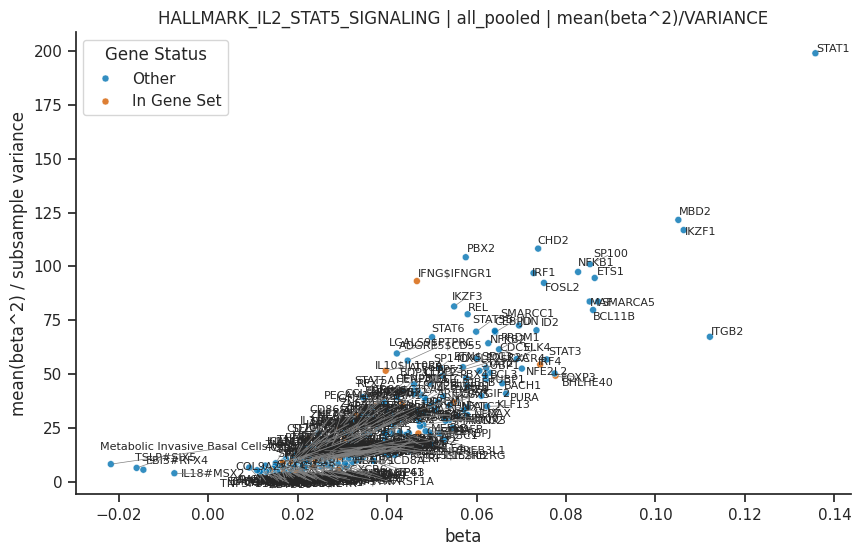

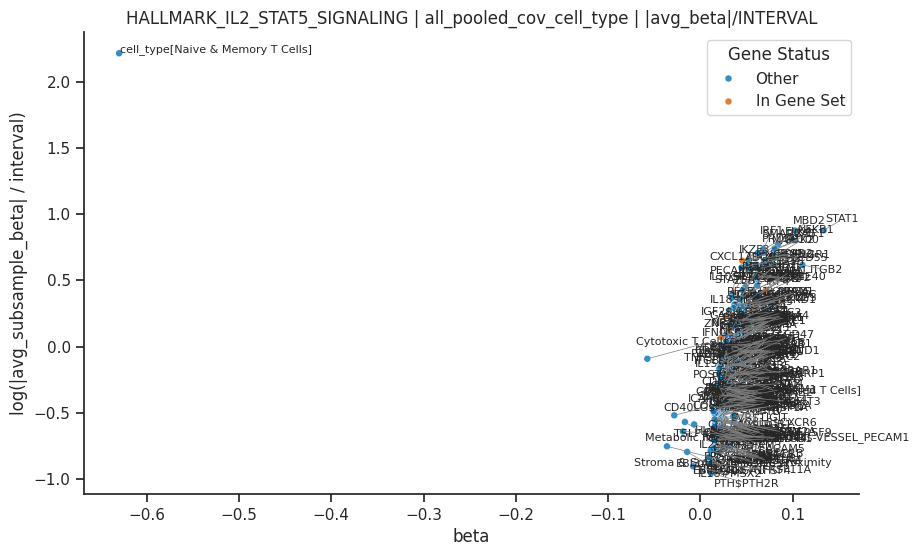

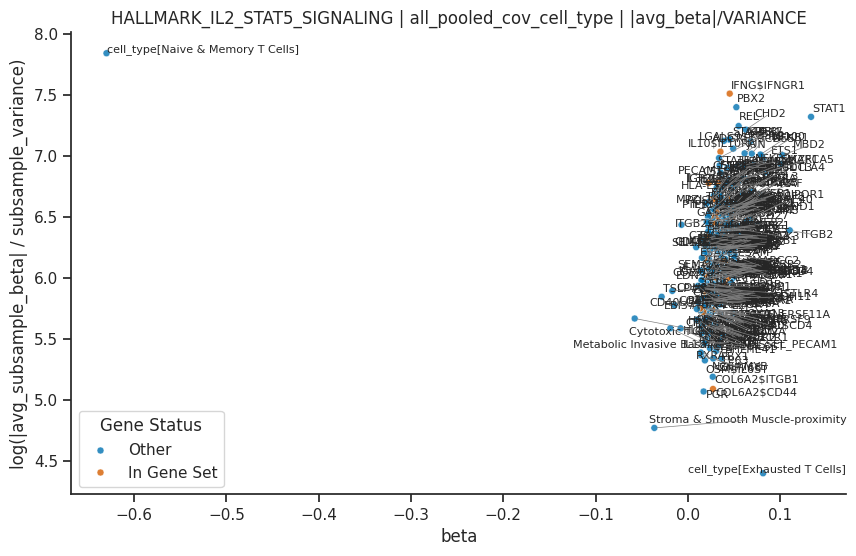

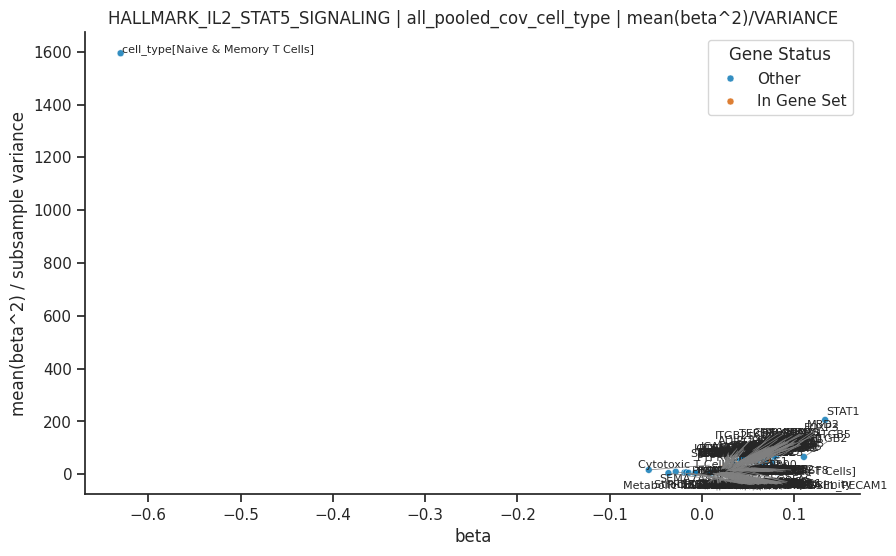

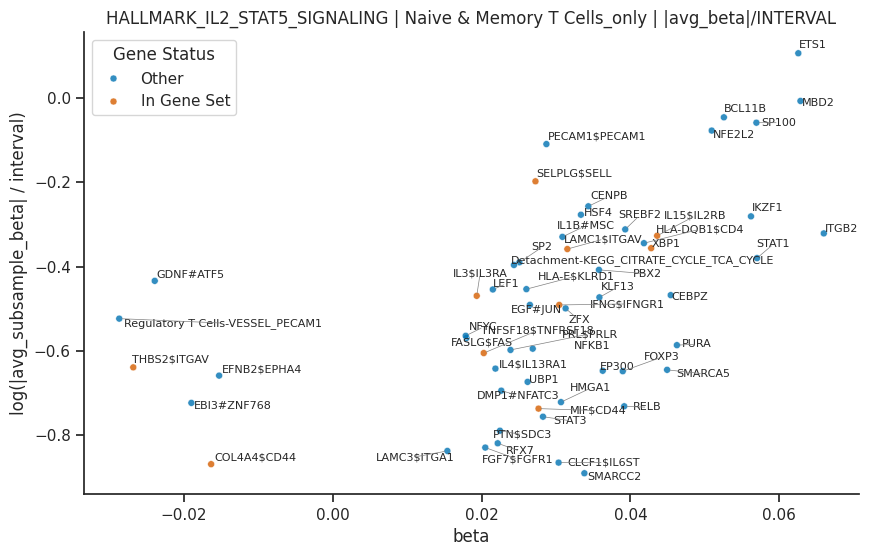

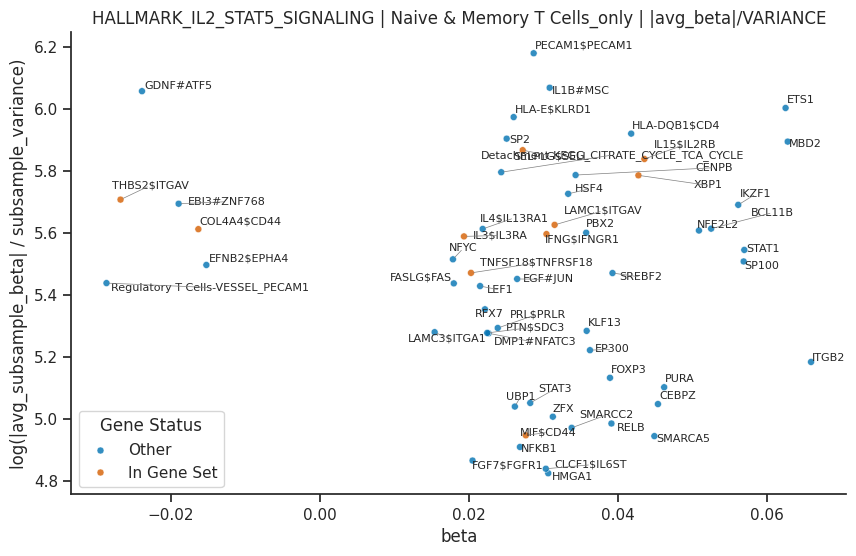

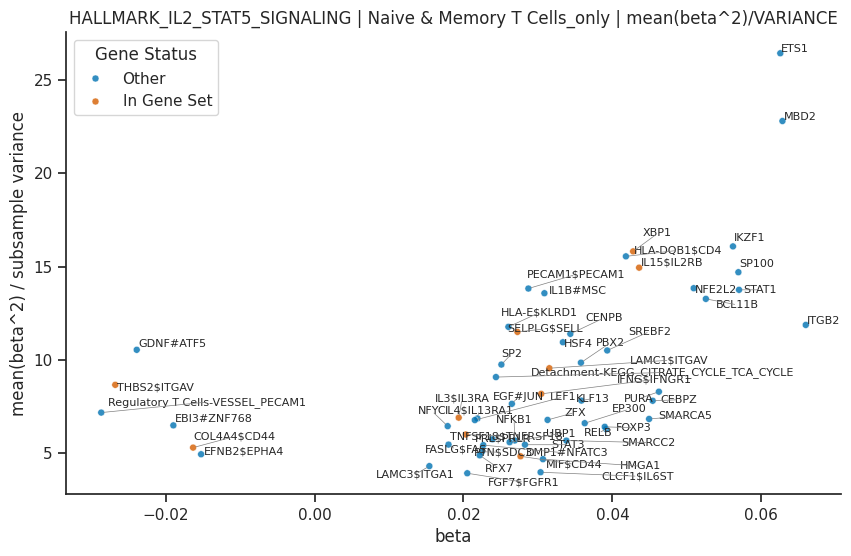

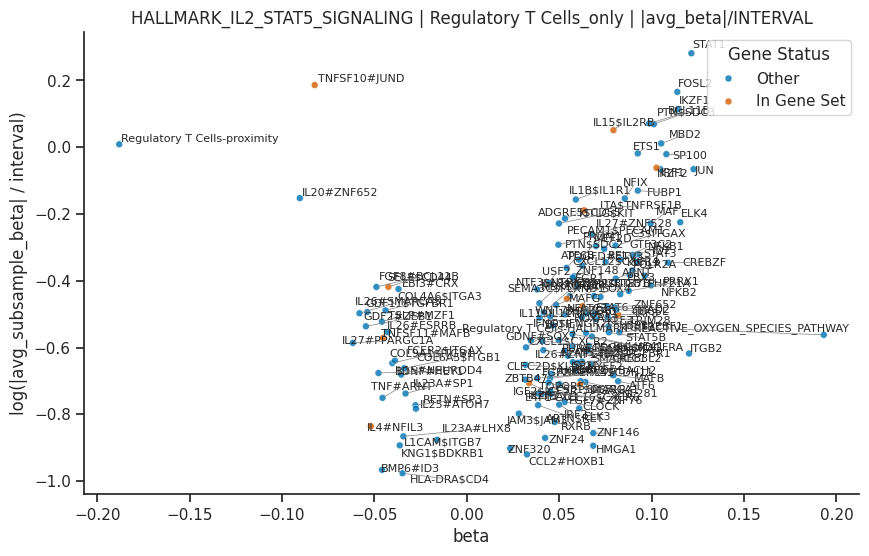

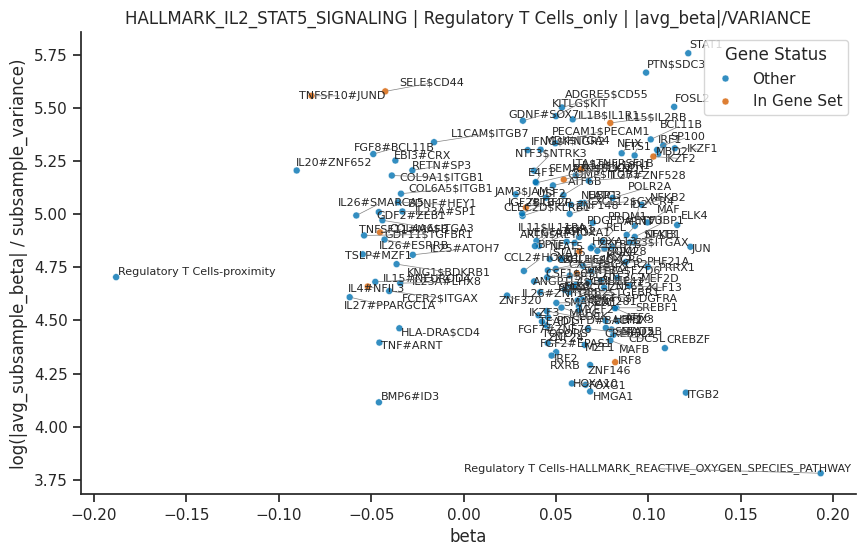

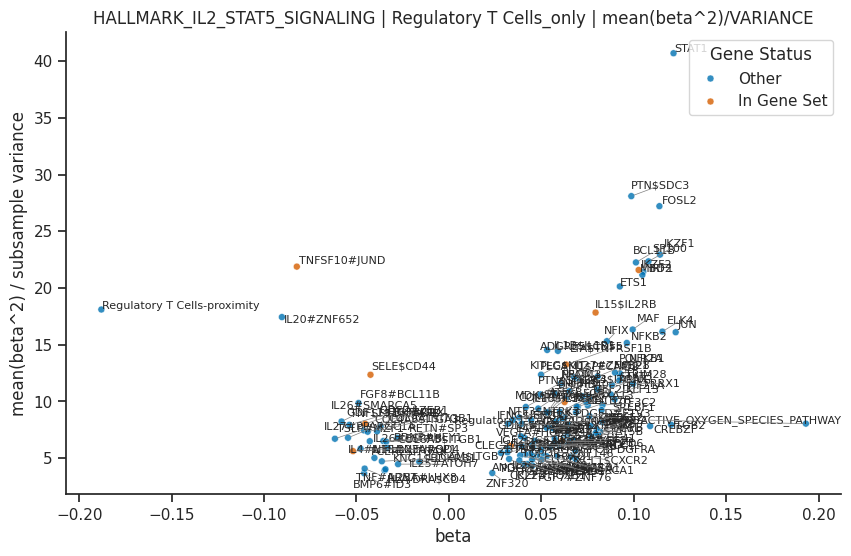

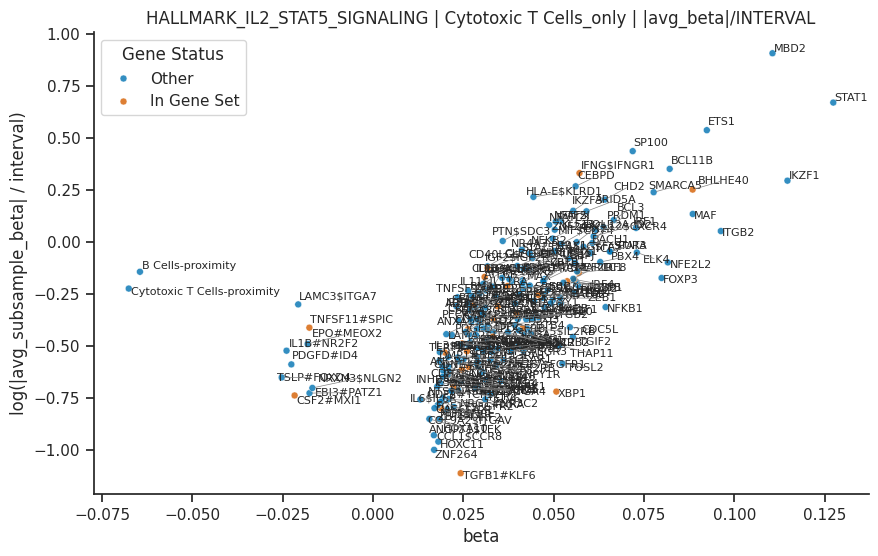

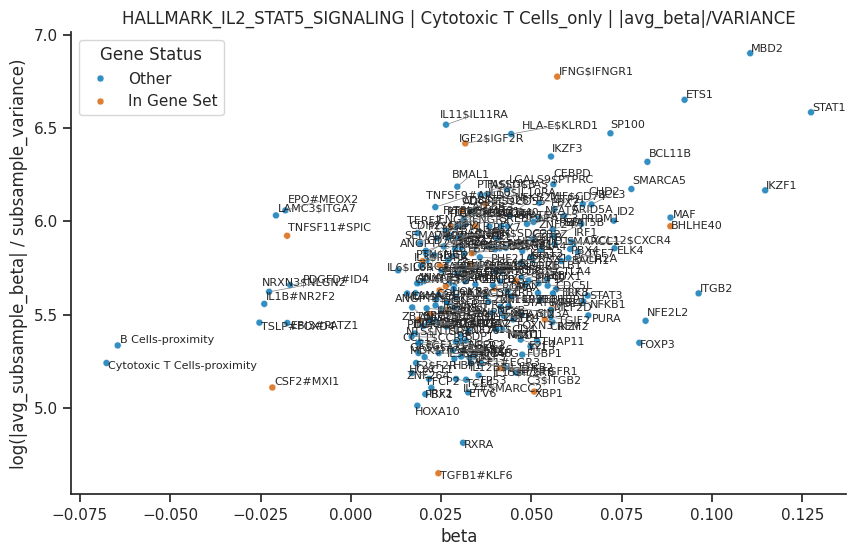

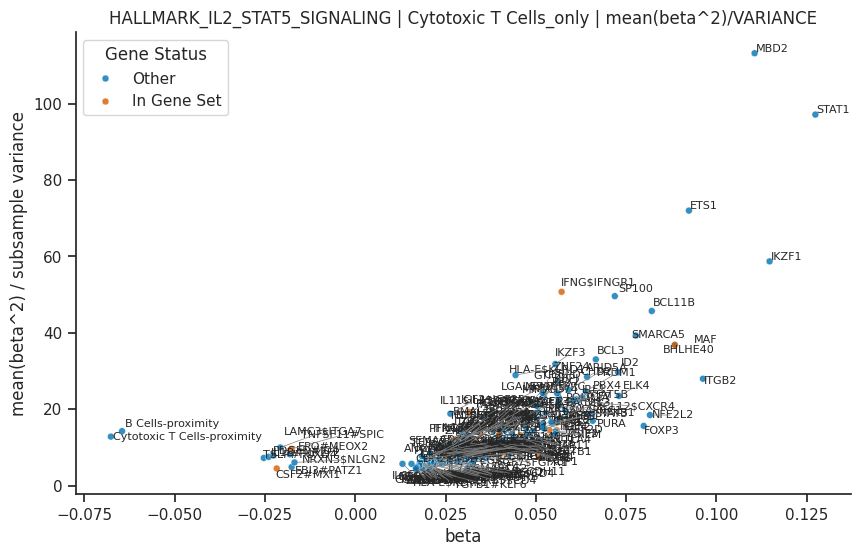

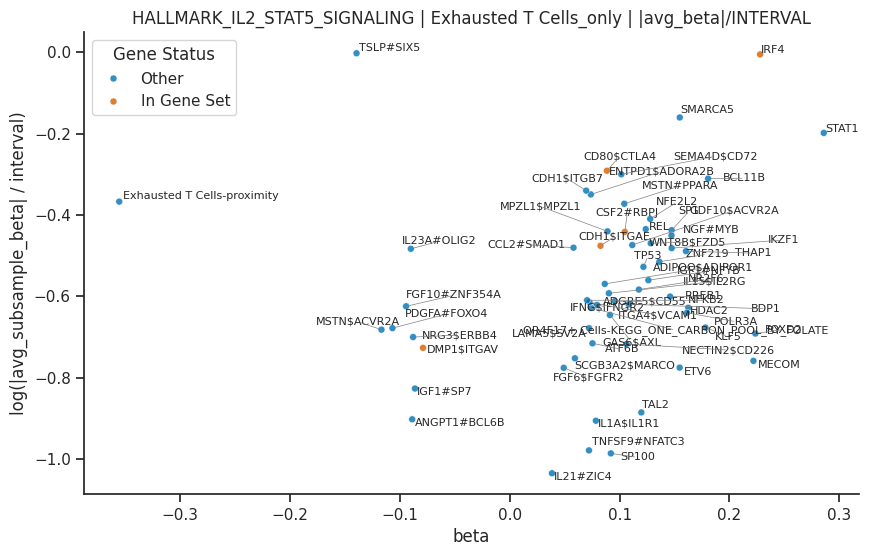

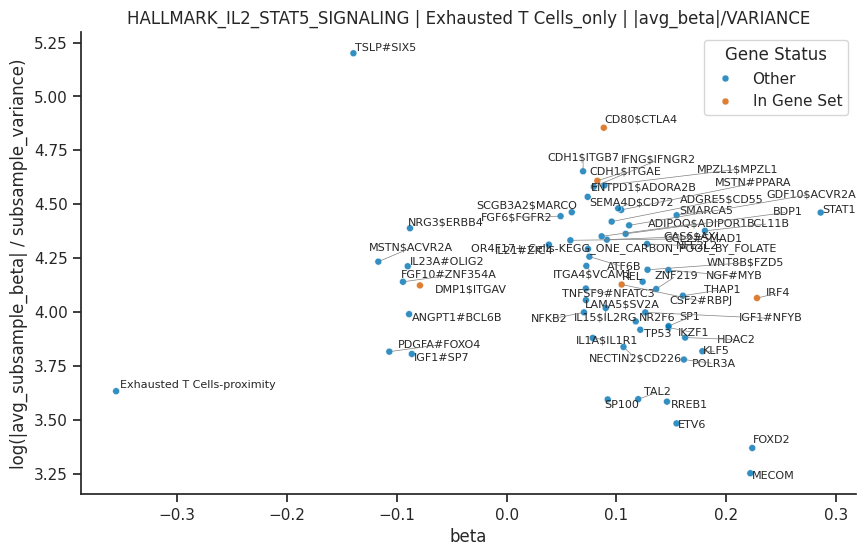

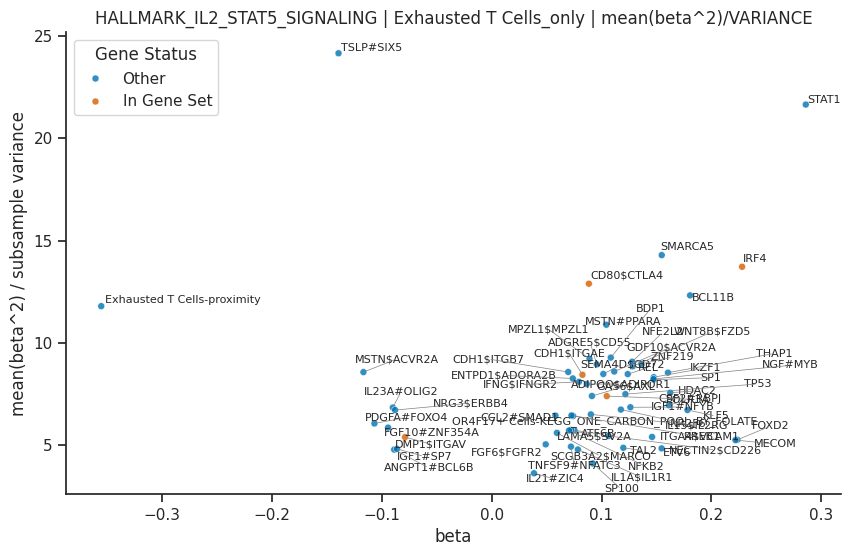

In [5]:
view('HALLMARK_IL2_STAT5_SIGNALING')

### KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY

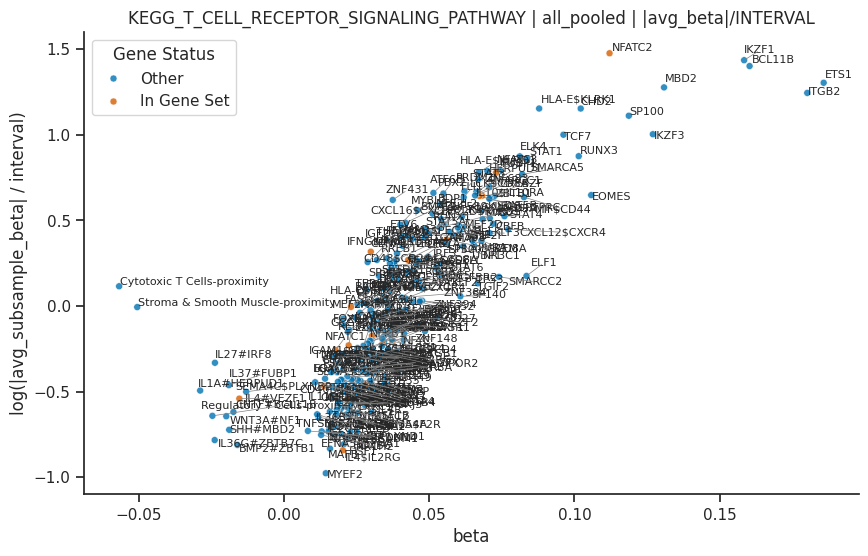

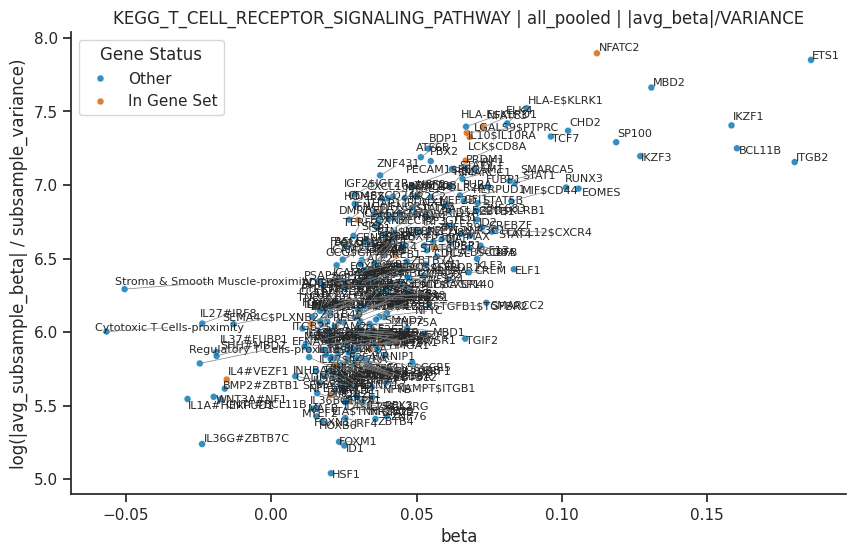

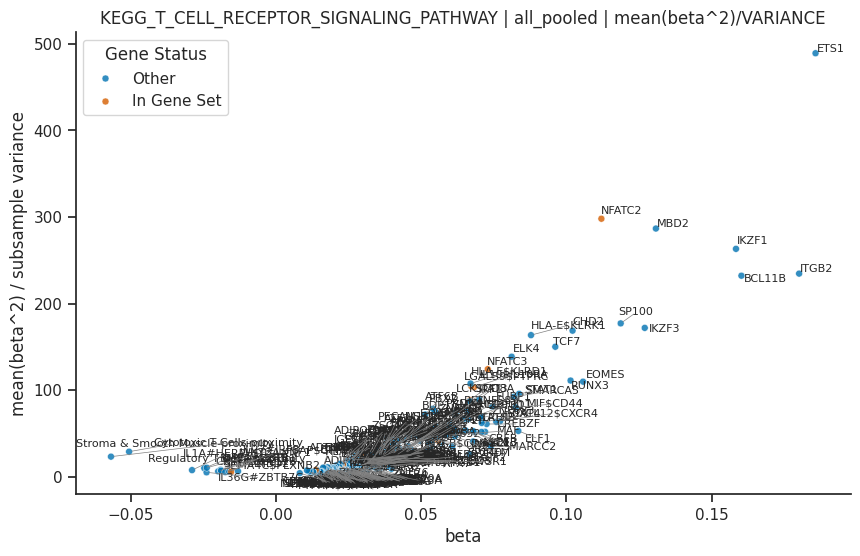

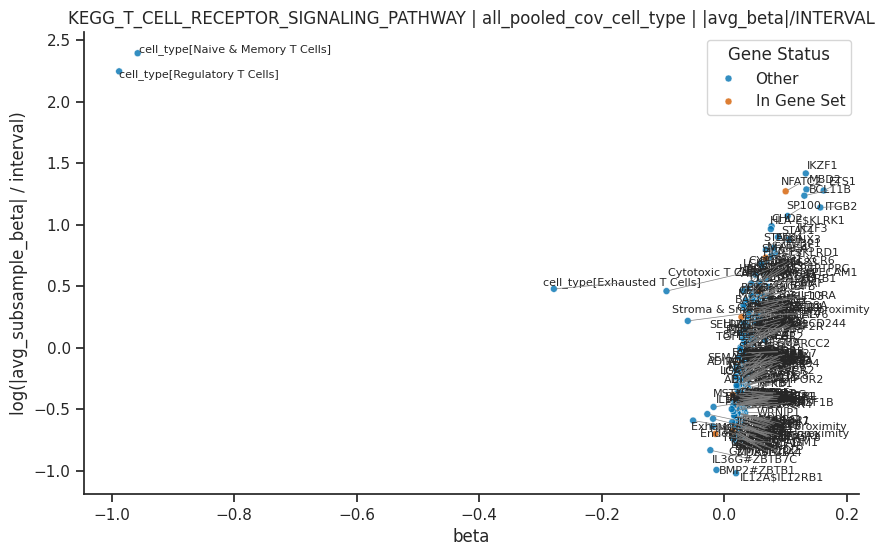

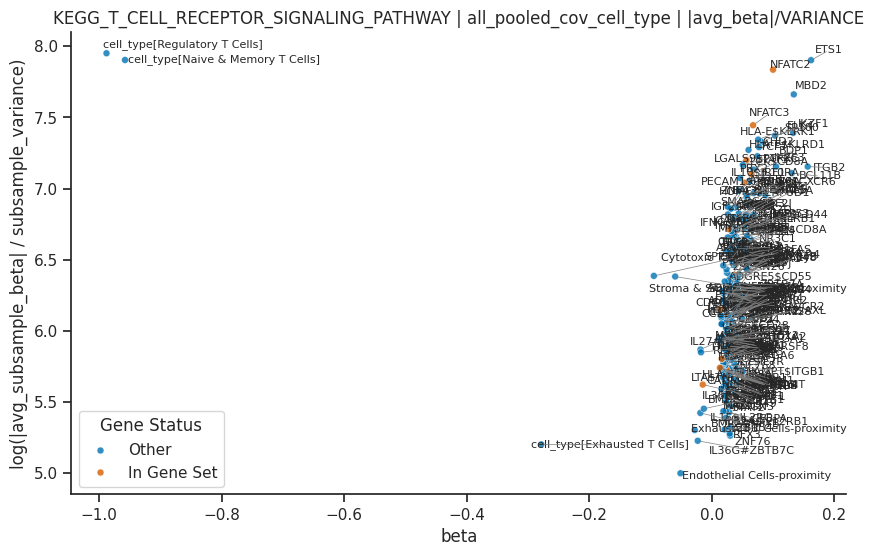

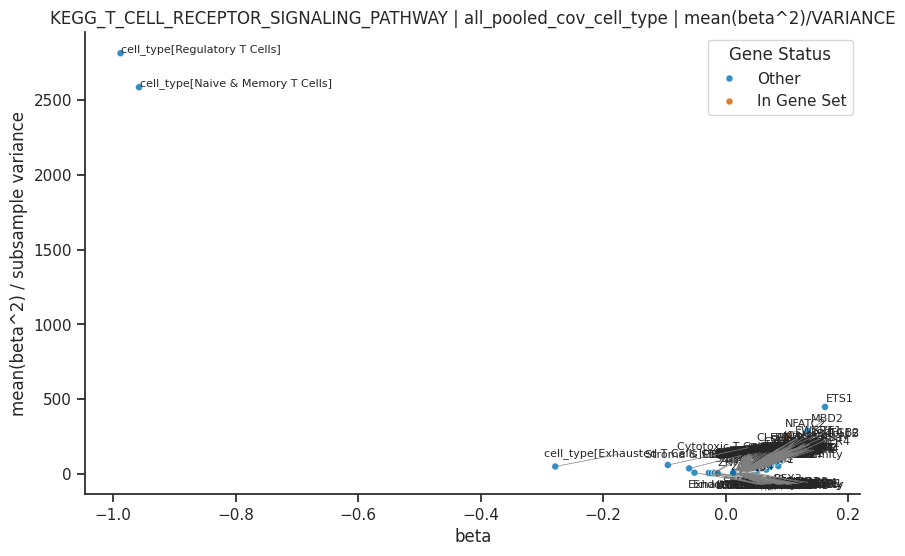

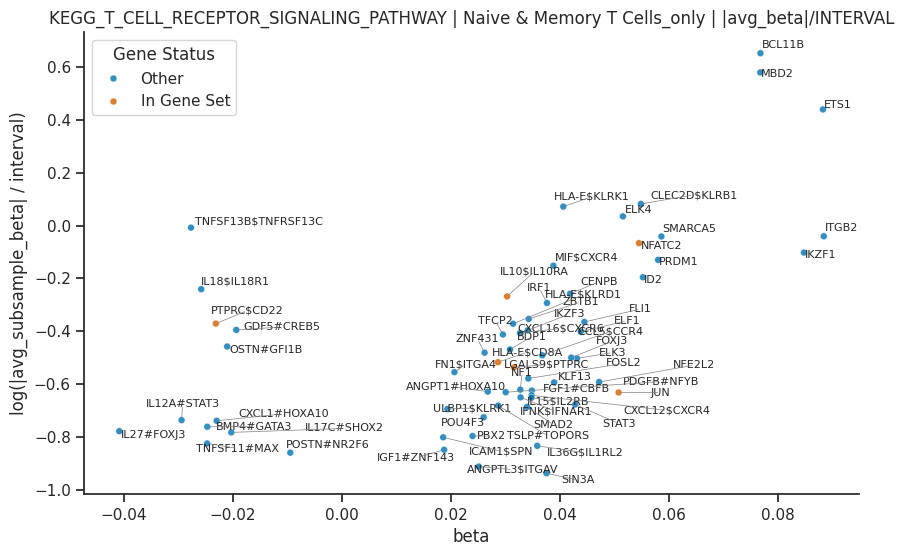

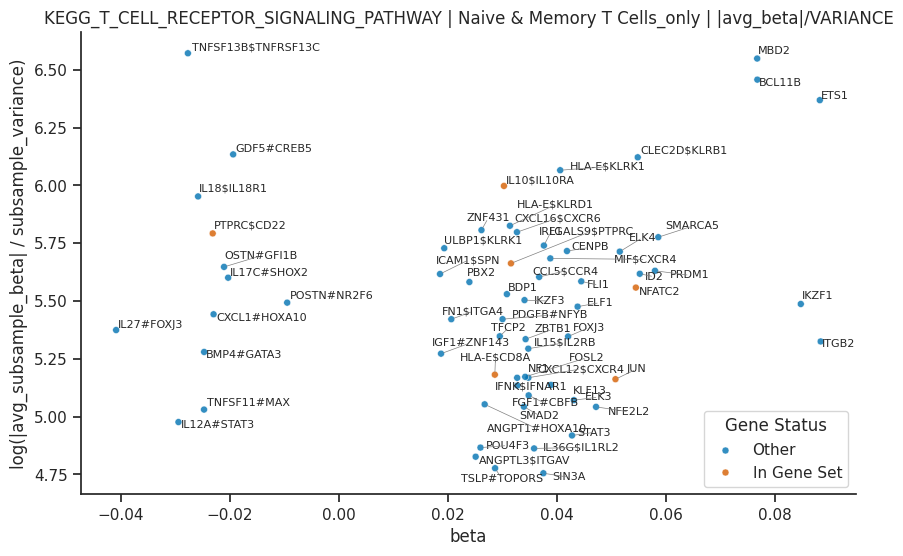

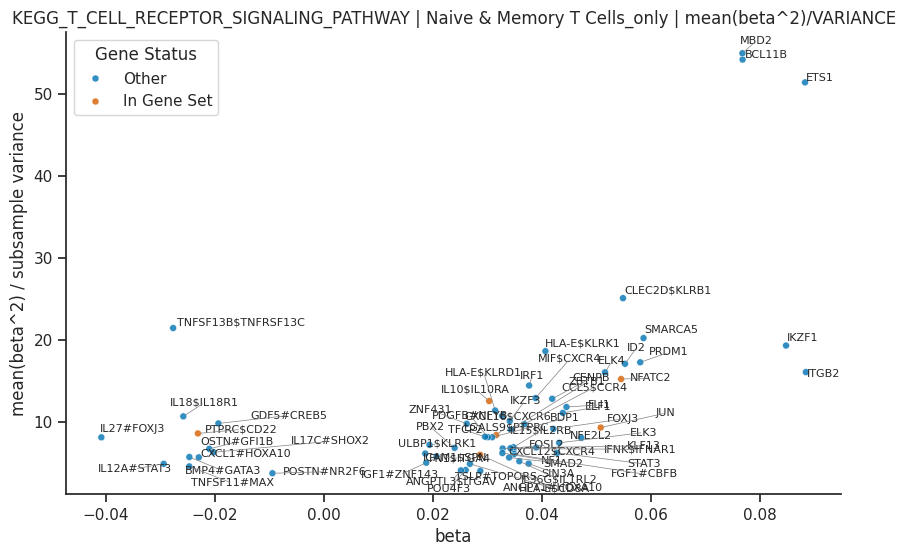

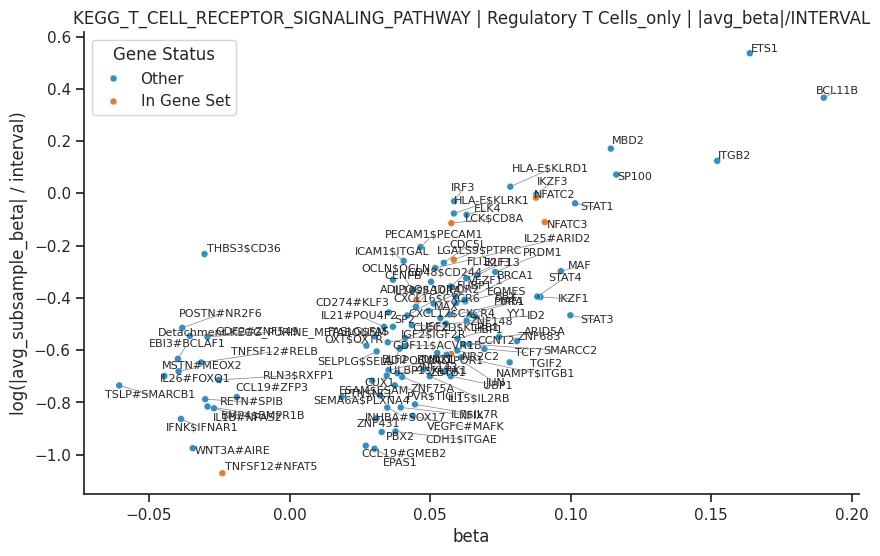

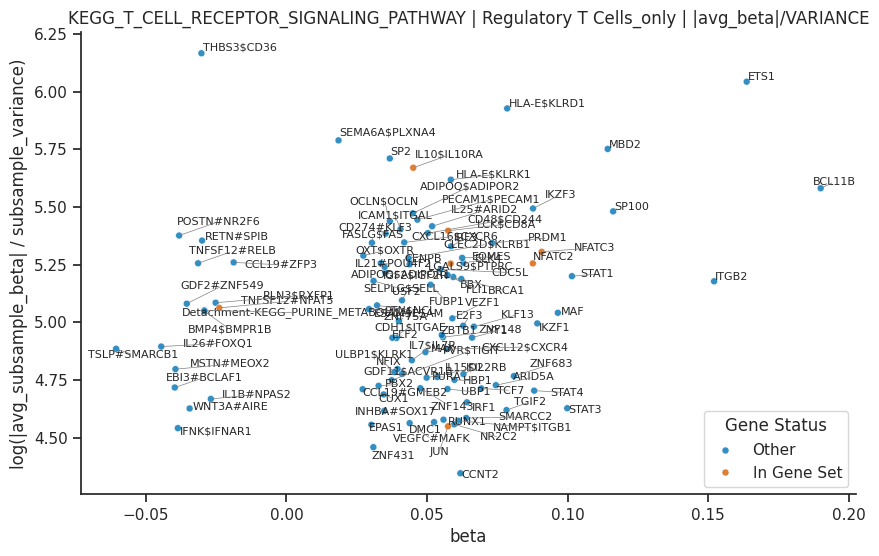

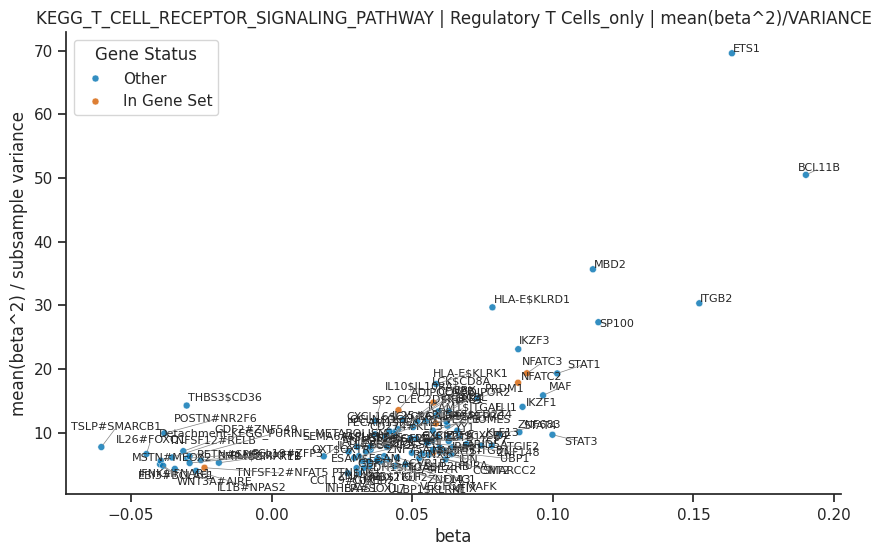

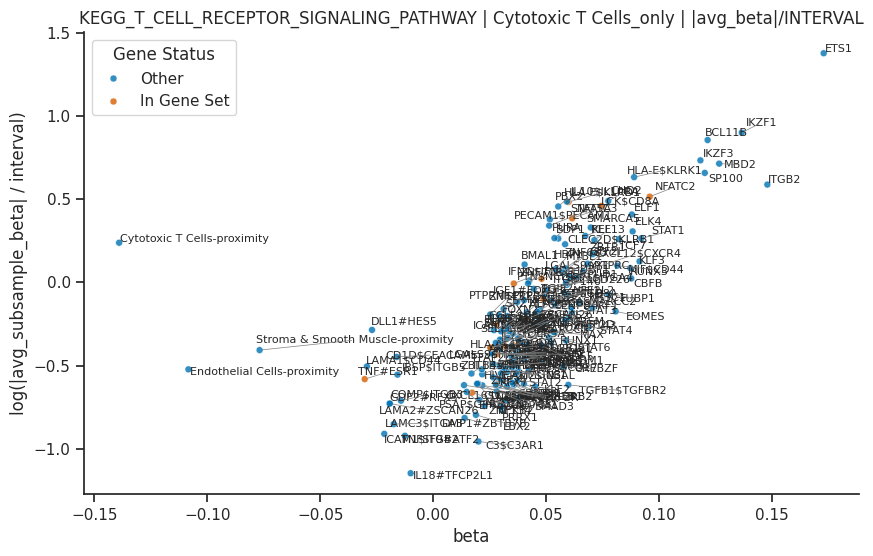

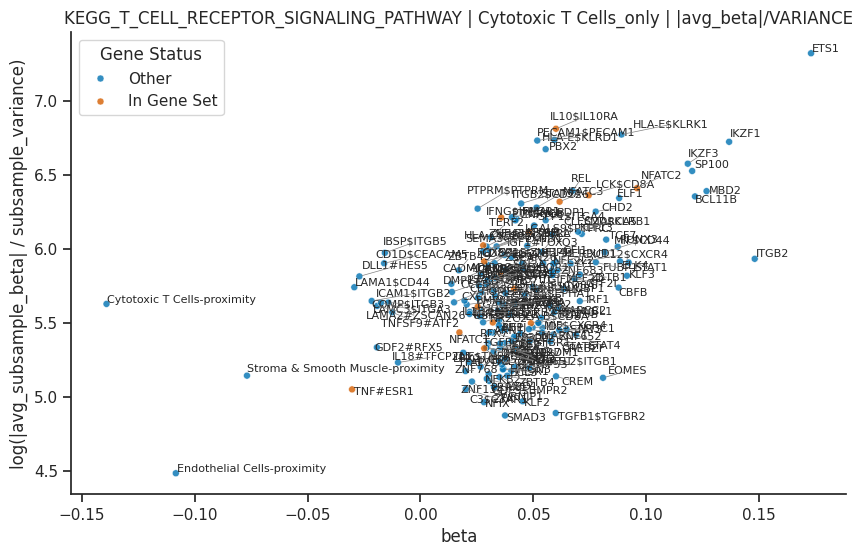

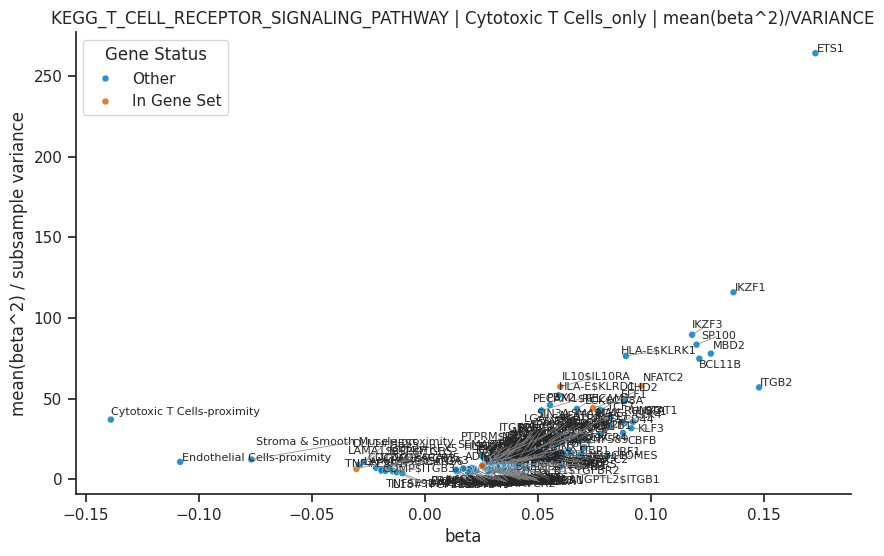

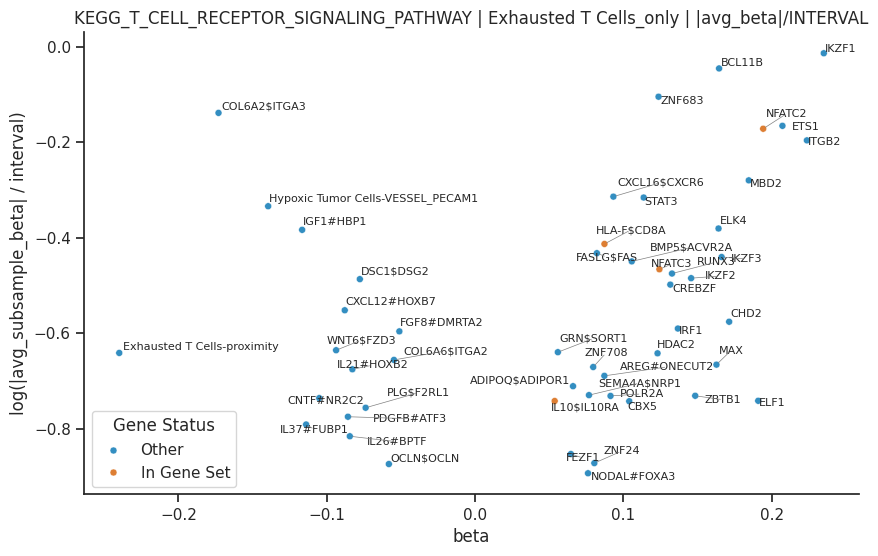

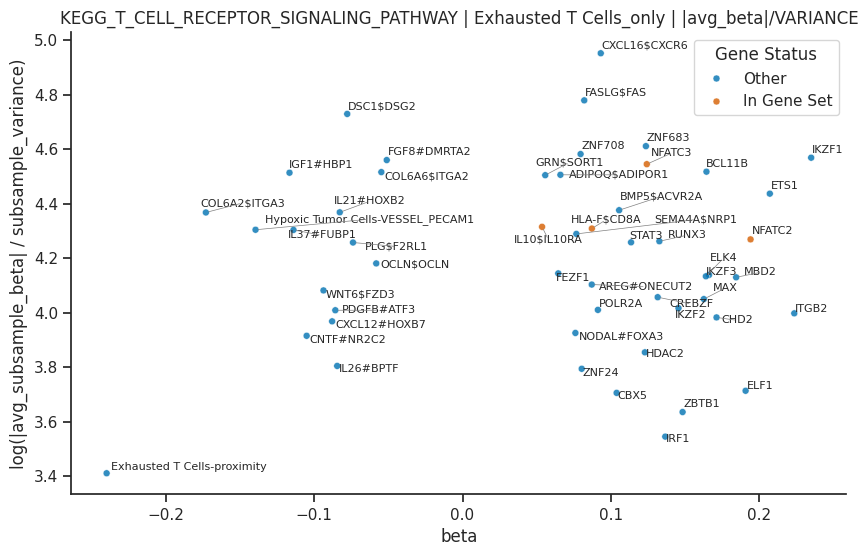

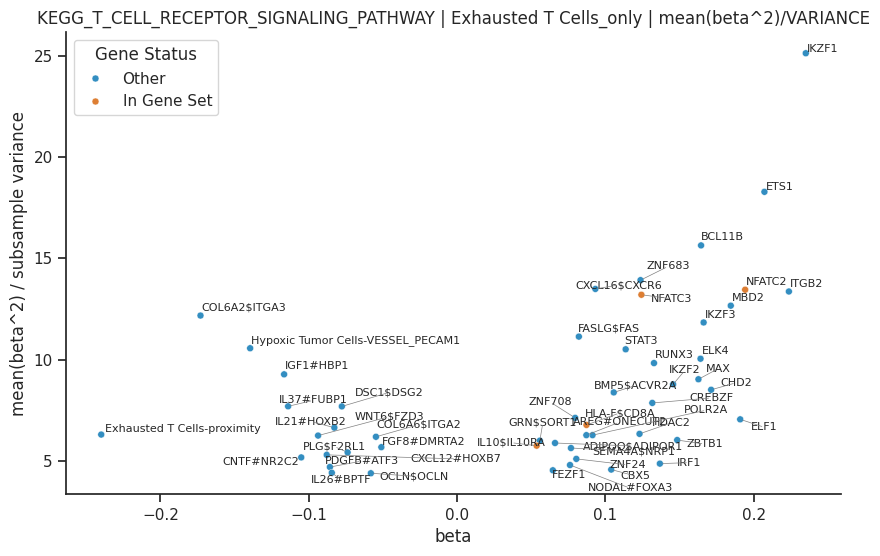

In [6]:
view('KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY')

### GOBP_T_CELL_MEDIATED_CYTOTOXICITY

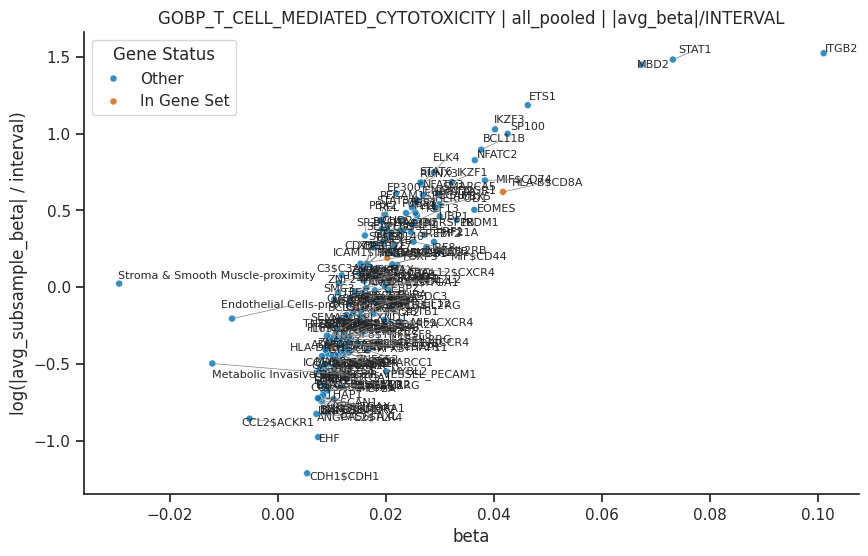

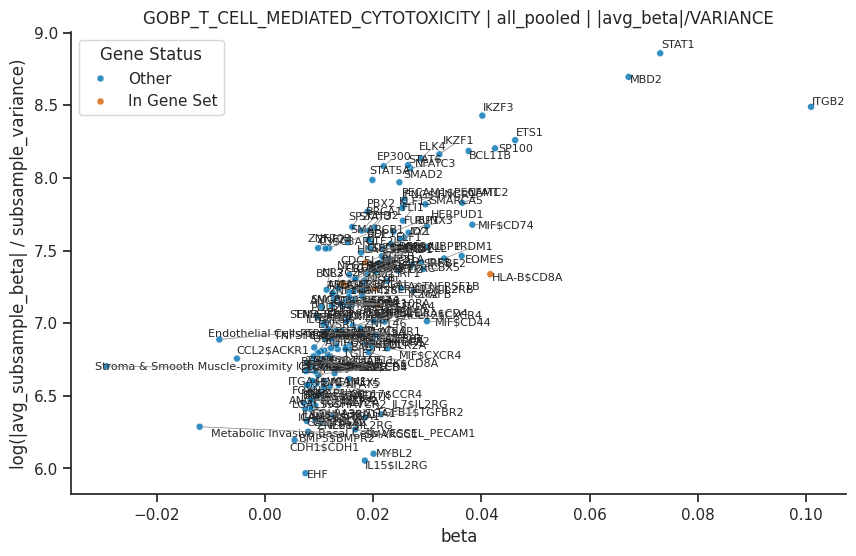

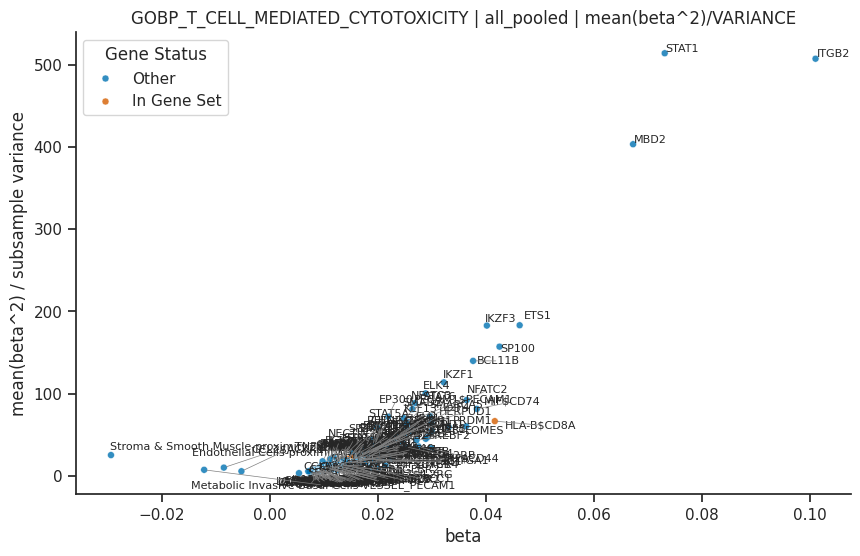

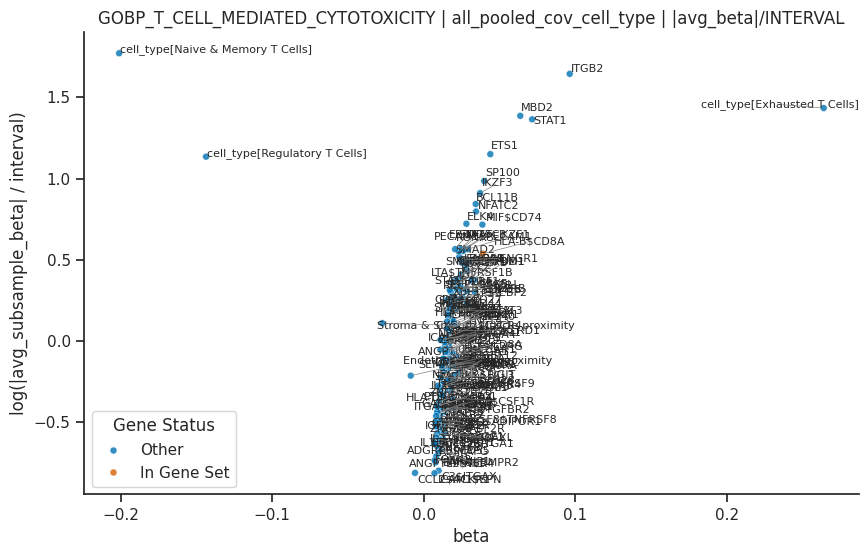

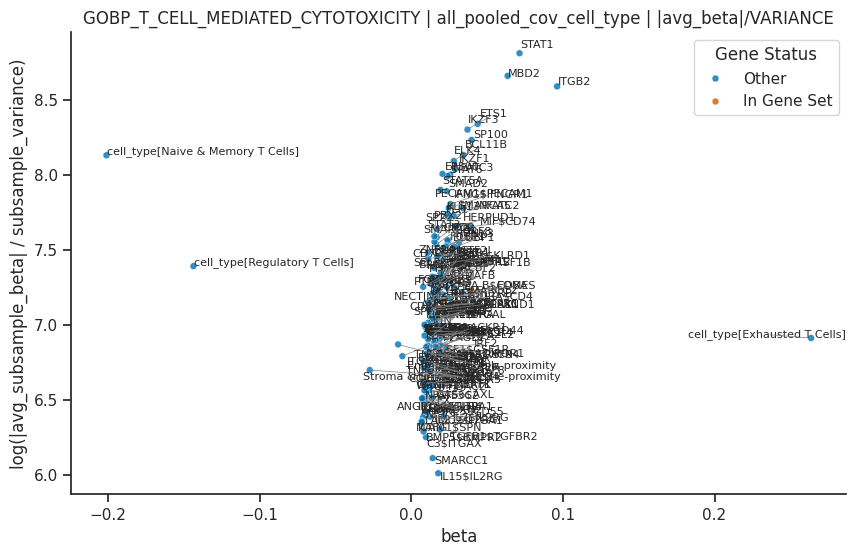

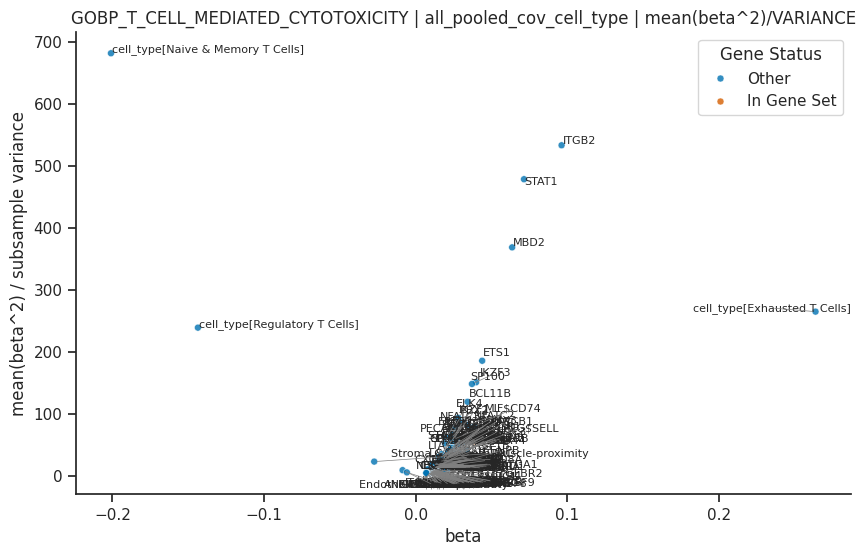

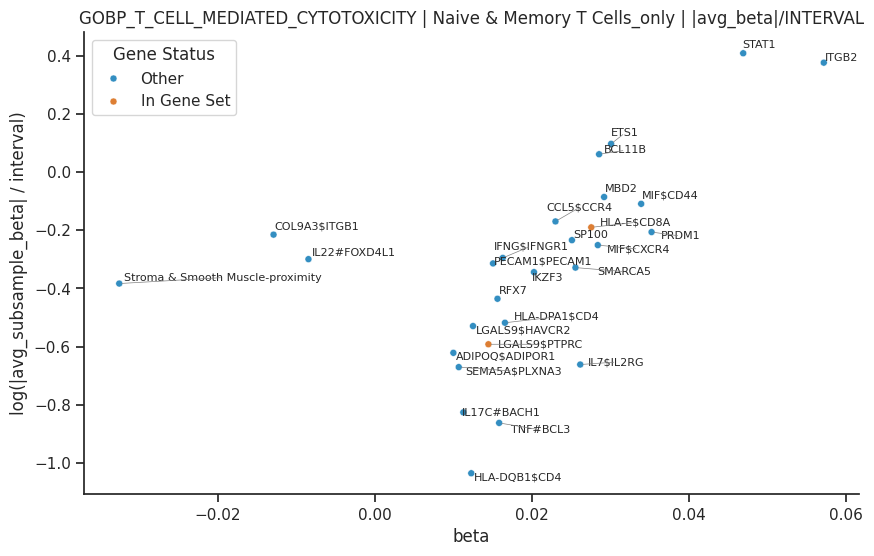

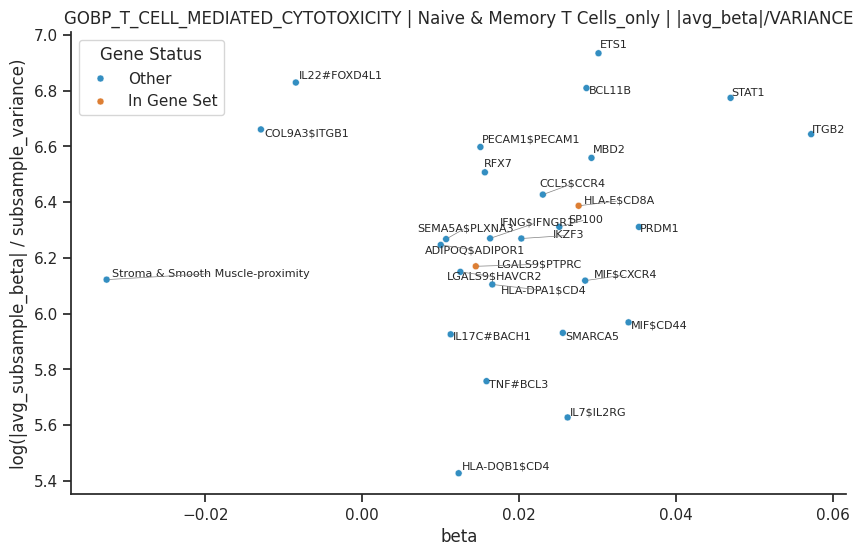

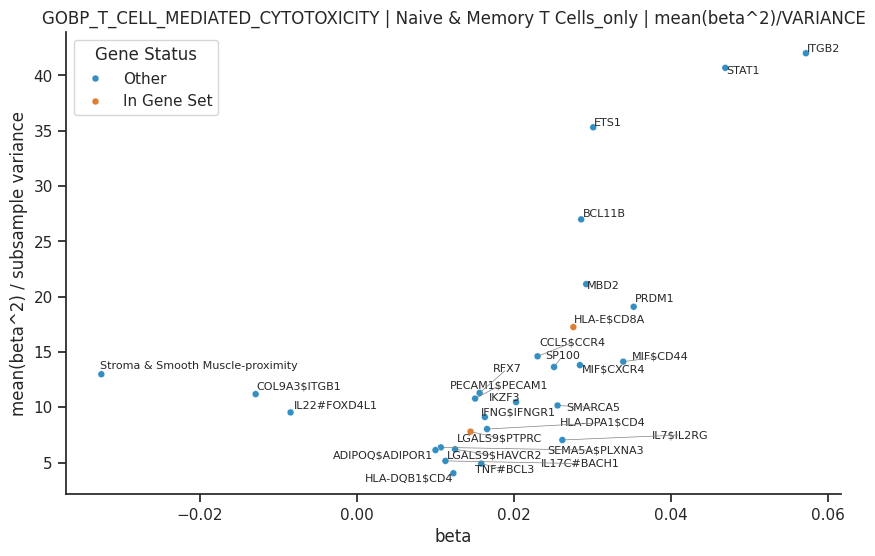

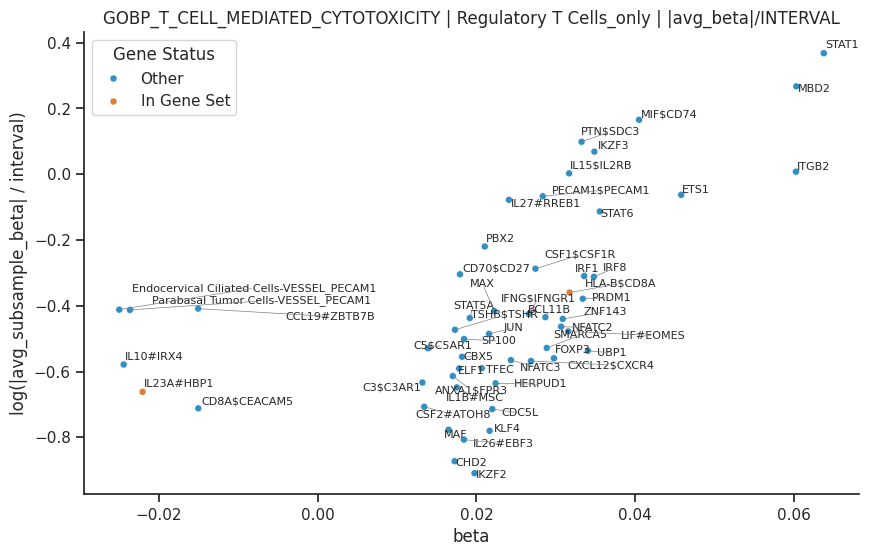

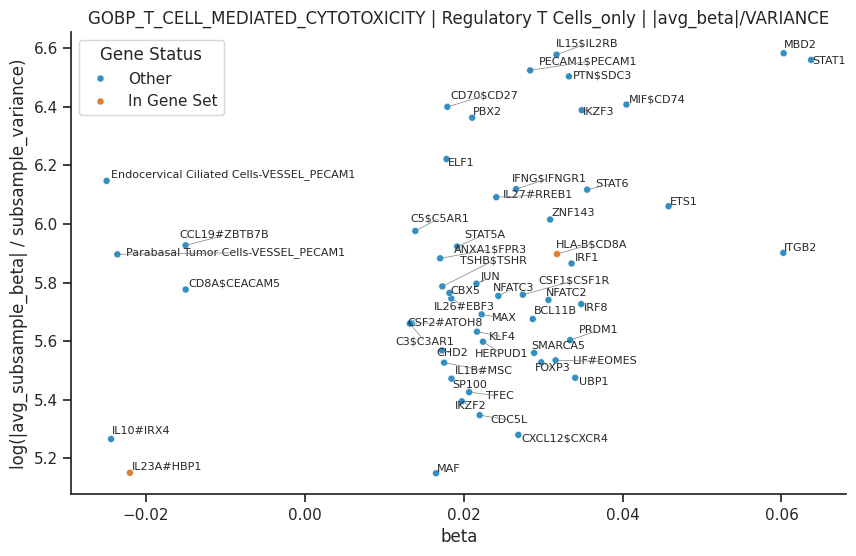

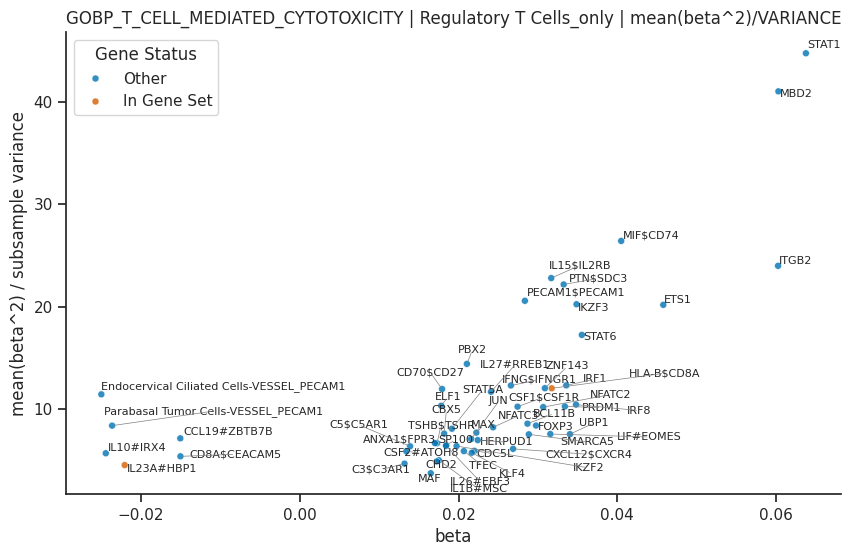

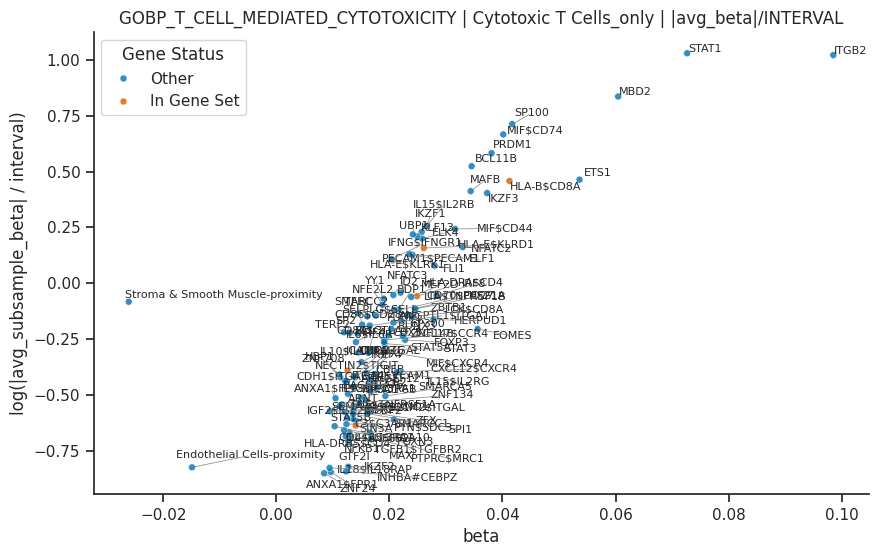

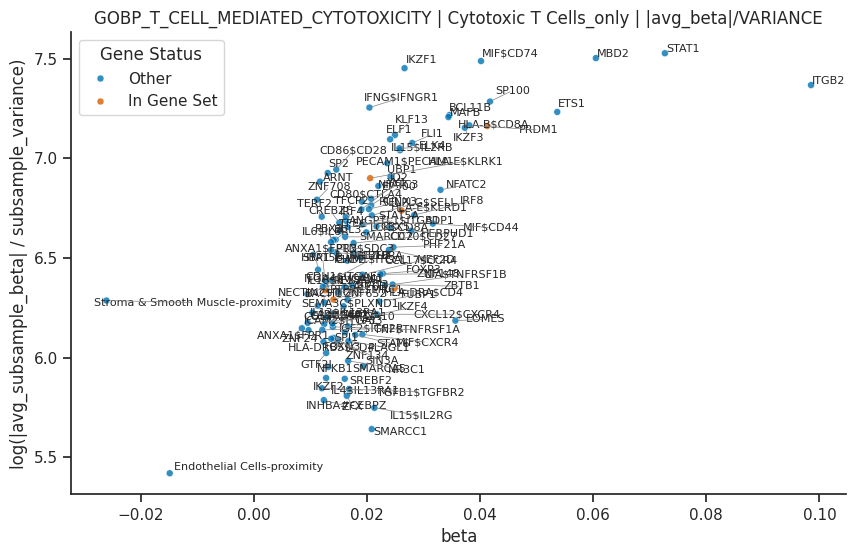

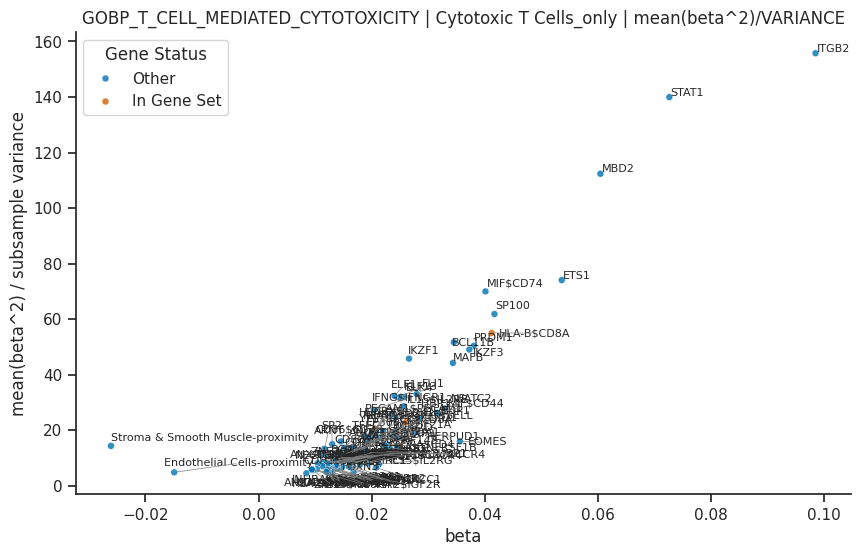

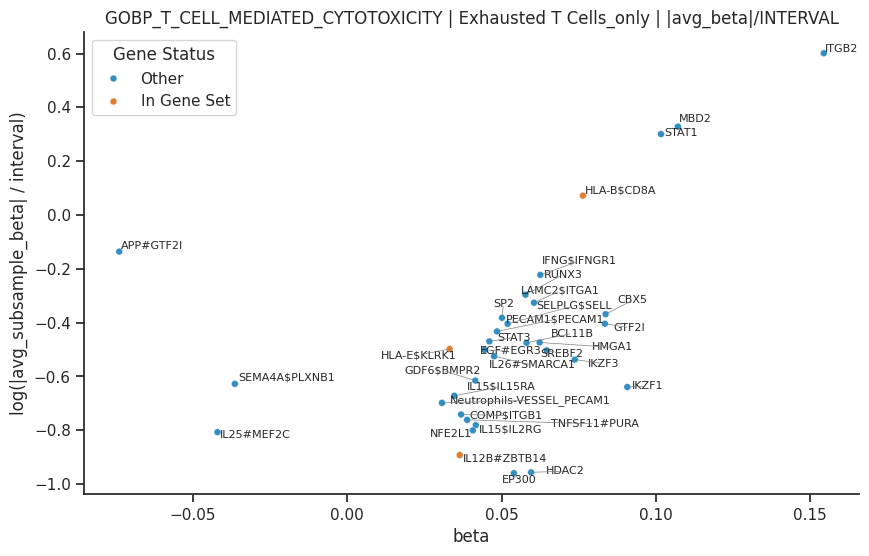

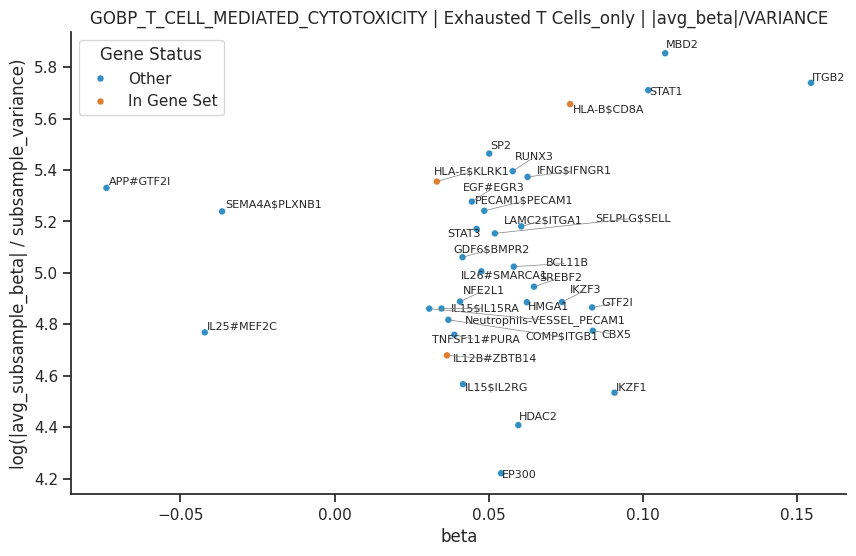

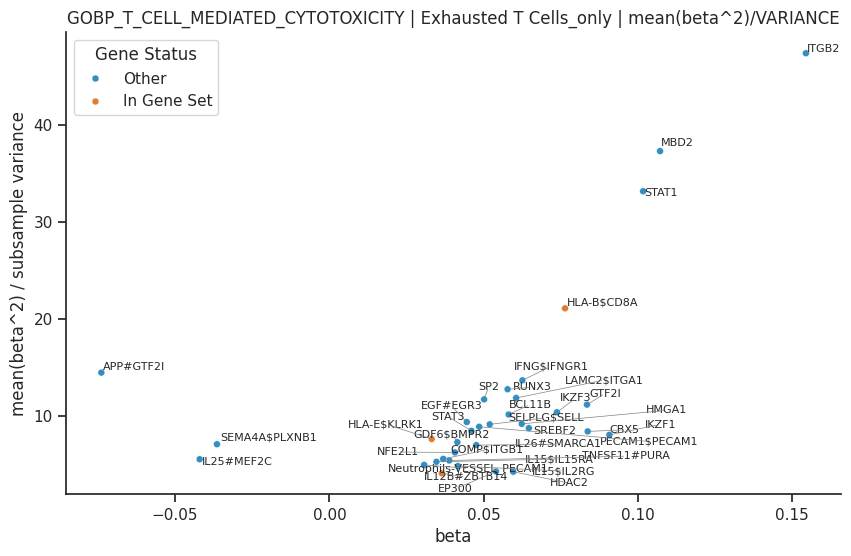

In [7]:
view('GOBP_T_CELL_MEDIATED_CYTOTOXICITY')

### KEGG_NATURAL_KILLER_CELL_MEDIATED_CYTOTOXICITY

not yet computed: KEGG_NATURAL_KILLER_CELL_MEDIATED_CYTOTOXICITY all_pooled_cov_cell_type
not yet computed: KEGG_NATURAL_KILLER_CELL_MEDIATED_CYTOTOXICITY Naive & Memory T Cells_only
not yet computed: KEGG_NATURAL_KILLER_CELL_MEDIATED_CYTOTOXICITY Regulatory T Cells_only
not yet computed: KEGG_NATURAL_KILLER_CELL_MEDIATED_CYTOTOXICITY Cytotoxic T Cells_only
not yet computed: KEGG_NATURAL_KILLER_CELL_MEDIATED_CYTOTOXICITY Exhausted T Cells_only


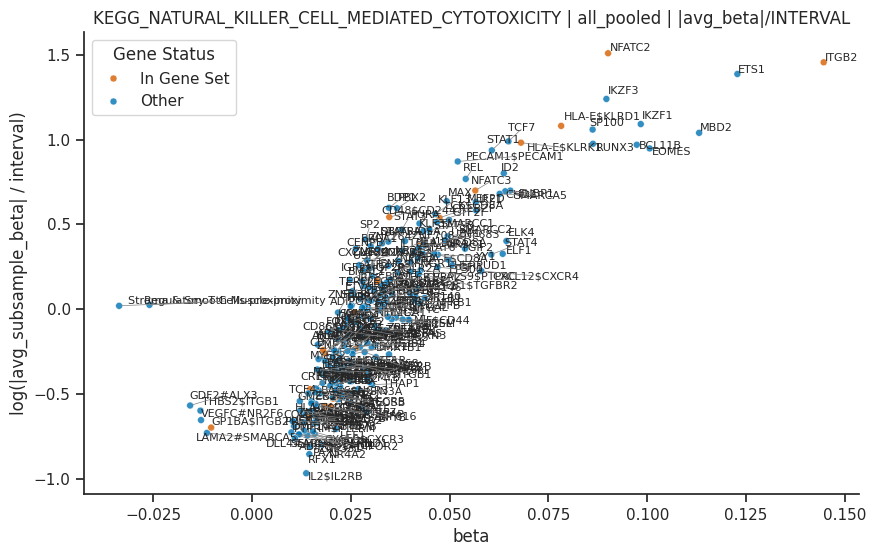

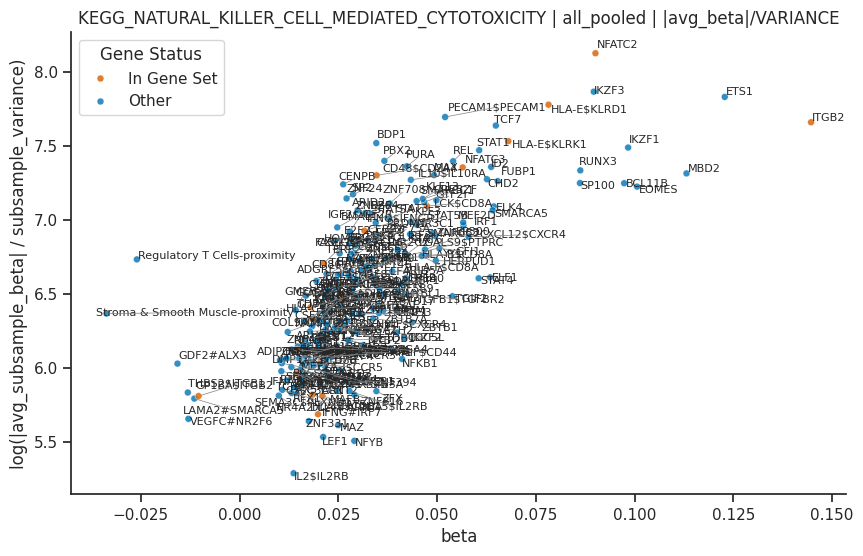

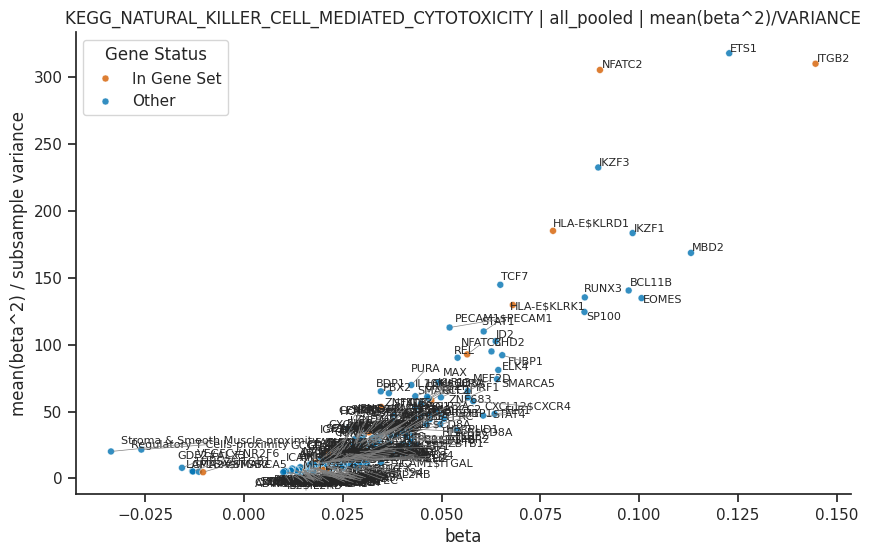

In [8]:
view('KEGG_NATURAL_KILLER_CELL_MEDIATED_CYTOTOXICITY')

### HALLMARK_TNFA_SIGNALING_VIA_NFKB

In [9]:
view('HALLMARK_TNFA_SIGNALING_VIA_NFKB')

not yet computed: HALLMARK_TNFA_SIGNALING_VIA_NFKB all_pooled
not yet computed: HALLMARK_TNFA_SIGNALING_VIA_NFKB all_pooled_cov_cell_type
not yet computed: HALLMARK_TNFA_SIGNALING_VIA_NFKB Naive & Memory T Cells_only
not yet computed: HALLMARK_TNFA_SIGNALING_VIA_NFKB Regulatory T Cells_only
not yet computed: HALLMARK_TNFA_SIGNALING_VIA_NFKB Cytotoxic T Cells_only
not yet computed: HALLMARK_TNFA_SIGNALING_VIA_NFKB Exhausted T Cells_only


### HALLMARK_INTERFERON_GAMMA_RESPONSE

In [10]:
view('HALLMARK_INTERFERON_GAMMA_RESPONSE')

not yet computed: HALLMARK_INTERFERON_GAMMA_RESPONSE all_pooled
not yet computed: HALLMARK_INTERFERON_GAMMA_RESPONSE all_pooled_cov_cell_type
not yet computed: HALLMARK_INTERFERON_GAMMA_RESPONSE Naive & Memory T Cells_only
not yet computed: HALLMARK_INTERFERON_GAMMA_RESPONSE Regulatory T Cells_only
not yet computed: HALLMARK_INTERFERON_GAMMA_RESPONSE Cytotoxic T Cells_only
not yet computed: HALLMARK_INTERFERON_GAMMA_RESPONSE Exhausted T Cells_only


### HALLMARK_INTERFERON_ALPHA_RESPONSE

In [11]:
view('HALLMARK_INTERFERON_ALPHA_RESPONSE')

not yet computed: HALLMARK_INTERFERON_ALPHA_RESPONSE all_pooled
not yet computed: HALLMARK_INTERFERON_ALPHA_RESPONSE all_pooled_cov_cell_type
not yet computed: HALLMARK_INTERFERON_ALPHA_RESPONSE Naive & Memory T Cells_only
not yet computed: HALLMARK_INTERFERON_ALPHA_RESPONSE Regulatory T Cells_only
not yet computed: HALLMARK_INTERFERON_ALPHA_RESPONSE Cytotoxic T Cells_only
not yet computed: HALLMARK_INTERFERON_ALPHA_RESPONSE Exhausted T Cells_only


### GOBP_CELL_KILLING

In [12]:
view('GOBP_CELL_KILLING')

not yet computed: GOBP_CELL_KILLING all_pooled
not yet computed: GOBP_CELL_KILLING all_pooled_cov_cell_type
not yet computed: GOBP_CELL_KILLING Naive & Memory T Cells_only
not yet computed: GOBP_CELL_KILLING Regulatory T Cells_only
not yet computed: GOBP_CELL_KILLING Cytotoxic T Cells_only
not yet computed: GOBP_CELL_KILLING Exhausted T Cells_only


### GOBP_GRANZYME_MEDIATED_PROGRAMMED_CELL_DEATH_SIGNALING_PATHWAY

In [13]:
view('GOBP_GRANZYME_MEDIATED_PROGRAMMED_CELL_DEATH_SIGNALING_PATHWAY')

not yet computed: GOBP_GRANZYME_MEDIATED_PROGRAMMED_CELL_DEATH_SIGNALING_PATHWAY all_pooled
not yet computed: GOBP_GRANZYME_MEDIATED_PROGRAMMED_CELL_DEATH_SIGNALING_PATHWAY all_pooled_cov_cell_type
not yet computed: GOBP_GRANZYME_MEDIATED_PROGRAMMED_CELL_DEATH_SIGNALING_PATHWAY Naive & Memory T Cells_only
not yet computed: GOBP_GRANZYME_MEDIATED_PROGRAMMED_CELL_DEATH_SIGNALING_PATHWAY Regulatory T Cells_only
not yet computed: GOBP_GRANZYME_MEDIATED_PROGRAMMED_CELL_DEATH_SIGNALING_PATHWAY Cytotoxic T Cells_only
not yet computed: GOBP_GRANZYME_MEDIATED_PROGRAMMED_CELL_DEATH_SIGNALING_PATHWAY Exhausted T Cells_only


### GOBP_LYMPHOCYTE_MEDIATED_IMMUNITY

In [14]:
view('GOBP_LYMPHOCYTE_MEDIATED_IMMUNITY')

not yet computed: GOBP_LYMPHOCYTE_MEDIATED_IMMUNITY all_pooled
not yet computed: GOBP_LYMPHOCYTE_MEDIATED_IMMUNITY all_pooled_cov_cell_type
not yet computed: GOBP_LYMPHOCYTE_MEDIATED_IMMUNITY Naive & Memory T Cells_only
not yet computed: GOBP_LYMPHOCYTE_MEDIATED_IMMUNITY Regulatory T Cells_only
not yet computed: GOBP_LYMPHOCYTE_MEDIATED_IMMUNITY Cytotoxic T Cells_only
not yet computed: GOBP_LYMPHOCYTE_MEDIATED_IMMUNITY Exhausted T Cells_only


## Negative controls

### HALLMARK_PANCREAS_BETA_CELLS

In [15]:
view('HALLMARK_PANCREAS_BETA_CELLS')

not yet computed: HALLMARK_PANCREAS_BETA_CELLS all_pooled
not yet computed: HALLMARK_PANCREAS_BETA_CELLS all_pooled_cov_cell_type
not yet computed: HALLMARK_PANCREAS_BETA_CELLS Naive & Memory T Cells_only
not yet computed: HALLMARK_PANCREAS_BETA_CELLS Regulatory T Cells_only
not yet computed: HALLMARK_PANCREAS_BETA_CELLS Cytotoxic T Cells_only
not yet computed: HALLMARK_PANCREAS_BETA_CELLS Exhausted T Cells_only


### HALLMARK_SPERMATOGENESIS

In [16]:
view('HALLMARK_SPERMATOGENESIS')

not yet computed: HALLMARK_SPERMATOGENESIS all_pooled
not yet computed: HALLMARK_SPERMATOGENESIS all_pooled_cov_cell_type
not yet computed: HALLMARK_SPERMATOGENESIS Naive & Memory T Cells_only
not yet computed: HALLMARK_SPERMATOGENESIS Regulatory T Cells_only
not yet computed: HALLMARK_SPERMATOGENESIS Cytotoxic T Cells_only
not yet computed: HALLMARK_SPERMATOGENESIS Exhausted T Cells_only
